# Modul 6 — Filter Spasial
**Nama:** Adam Bahy Maulana  |  **NIM:** 244107020207  |  No. Absen: 2

Low Pass Filter, High Pass Filter, Point Detection, Line Detection, Edge Detection.

## 1. Identitas & Lingkungan

In [ ]:
import platform, datetime, hashlib, os
NAMA  = "Adam Bahy Maulana"
NIM   = "244107020207"
NO_ABSEN = 2
N     = int(NIM[-3:])          # 207
TOKEN = hashlib.sha256((NIM + '|' + datetime.date.today().isoformat()).encode()).hexdigest()[:16]
print("Nama :", NAMA)
print("NIM  :", NIM, "| No. Absen:", NO_ABSEN)
print("N    :", N, "| sisa N mod 4 =", N % 4, "| sisa N mod 2 =", N % 2)
print("Token:", TOKEN)
print("Waktu:", datetime.datetime.now().astimezone().isoformat())
print("Sistem:", platform.platform(), "| Python", platform.python_version())

Nama : Adam Bahy Maulana
NIM  : 244107020207 | No. Absen: 2
N    : 207 | sisa N mod 4 = 3 | sisa N mod 2 = 1
Token: aaaf491ba3010025
Waktu: 2026-10-02T22:55:59.644604+07:00
Sistem: Windows-10-10.0.26200-SP0 | Python 3.11.16


## 2. Import library & lokasi citra

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    IMAGES = '/content/drive/MyDrive/Polinema/Kuliah/PCVK/Images'
else:
    IMAGES = os.environ.get('LOCAL_DIR', os.path.abspath('Week 6/materi'))

OUT = os.path.join(IMAGES, 'out')
os.makedirs(OUT, exist_ok=True)
print("Mode   :", "Colab" if IN_COLAB else "Lokal")
print("Images :", IMAGES)
print("Output :", OUT)
print("Isi    :", sorted(os.listdir(IMAGES))[:12])

Mode   : Lokal
Images : C:\Kuliah\Tingkat 3\PCVK\Week 6\materi
Output : C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out
Isi    : ['djawatan.jpg', 'kue.JPG', 'lena.jpg', 'mandrill.tiff', 'out', 'pola.png', 'street.jpg']


## 3. Fungsi bantu

In [ ]:
FIG = [0]
def simpan(fig, nama):
    FIG[0] += 1
    p = os.path.join(OUT, "%02d_%s.png" % (FIG[0], nama))
    fig.savefig(p, dpi=110, bbox_inches='tight')
    return p

def show_side_by_side(images, titles, figsize=(15, 5), nama=None):
    fig = plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        ax = plt.subplot(1, len(images), i + 1)
        if img.ndim == 2:
            ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        ax.set_title(NIM + " - " + title)
        ax.axis('off')
    plt.tight_layout()
    if nama:
        print("disimpan:", simpan(fig, nama))
    plt.show()

def show_gray(img, title="", nama=None, figsize=(6, 6)):
    fig = plt.figure(figsize=figsize)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title(NIM + " - " + title if title else NIM)
    plt.axis('off')
    if nama:
        print("disimpan:", simpan(fig, nama))
    plt.show()

## 4. Fungsi konvolusi tanpa library

Parameter: citra masukan,
kernel, `stride`, dan `padding`. Padding memakai `np.pad(mode='edge')`, yaitu
duplikasi elemen pinggir.

In [ ]:
def convolution2d(image, kernel, stride=1, padding=0):
    """Konvolusi 2D dari nol — tanpa cv.filter2D atau metode konvolusi OpenCV."""
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    img = np.asarray(image, dtype=np.float64)
    if padding > 0:
        img = np.pad(img, padding, mode='edge')

    oh = (img.shape[0] - kh) // stride + 1
    ow = (img.shape[1] - kw) // stride + 1
    out = np.zeros((oh, ow), dtype=np.float64)

    for x in range(oh):                 # baris keluaran
        for y in range(ow):             # kolom keluaran
            total = 0.0
            for k1 in range(kh):
                for k2 in range(kw):
                    total += kernel[k1, k2] * img[x * stride + k1, y * stride + k2]
            out[x, y] = total

    return np.clip(out, 0, 255).astype(np.uint8)

# Uji kernel identitas: keluaran harus sama dengan bagian tengah citra masukan
_u = np.arange(25, dtype=np.uint8).reshape(5, 5)
_k = np.zeros((3, 3)); _k[1, 1] = 1
assert np.array_equal(convolution2d(_u, _k), _u[1:4, 1:4]), "kernel identitas gagal"
print("Uji kernel identitas lolos, bentuk keluaran:", convolution2d(_u, _k).shape)

Uji kernel identitas lolos, bentuk keluaran: (3, 3)


### 4.1 Verifikasi silang terhadap `cv.filter2D`

Dilakukan pada potongan 64 x 64 piksel karena perulangan bersarang mahal. Untuk
`padding = 1` pada kernel 3 x 3, border `cv.filter2D` diset `BORDER_REPLICATE`
yang perilakunya sama dengan `np.pad(mode='edge')`.

In [ ]:
img = cv.imread(os.path.join(IMAGES, 'mandrill.tiff'))
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
print("mandrill:", img.shape, "-> keabuan:", img_gray.shape)

k_sharpen = np.array([[0, -1, 0],
                      [-1, 5, -1],
                      [0, -1, 0]], dtype=np.float64)

kecil = img_gray[:64, :64]
manual = convolution2d(kecil, k_sharpen, 1, 1)
lib    = cv.filter2D(kecil, -1, k_sharpen, borderType=cv.BORDER_REPLICATE)
selisih = int(np.abs(manual.astype(int) - lib.astype(int)).max())
print("manual:", manual.shape, "| filter2D:", lib.shape, "| selisih maksimum:", selisih)

mandrill: (512, 512, 3) -> keabuan: (512, 512)
manual: (64, 64) | filter2D: (64, 64) | selisih maksimum: 0


## 5. Praktikum Filter (langkah 3 modul)

In [ ]:
KERNEL = {
    'Average 3x3': np.ones((3, 3), np.float64) / 9.0,
    'Low Pass':    np.array([[1, 1, 1], [1, 4, 1], [1, 1, 1]], np.float64) / 12.0,
    'High Pass':   np.array([[-1, 0, 1], [-1, 0, 3], [-3, 0, 1]], np.float64),
    'Sharpen':     np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float64),
    'Emboss':      np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], np.float64),
    'Sobel Kx':    np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], np.float64),
    'Laplacian':   np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], np.float64),
    'Point':       np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], np.float64),
}
for k, v in KERNEL.items():
    print("%-12s jumlah koefisien = %6.3f" % (k, v.sum()))

Average 3x3  jumlah koefisien =  1.000
Low Pass     jumlah koefisien =  1.000
High Pass    jumlah koefisien =  0.000
Sharpen      jumlah koefisien =  1.000
Emboss       jumlah koefisien =  1.000
Sobel Kx     jumlah koefisien =  0.000
Laplacian    jumlah koefisien =  0.000
Point        jumlah koefisien =  0.000


disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\01_basic_lp_hp.png


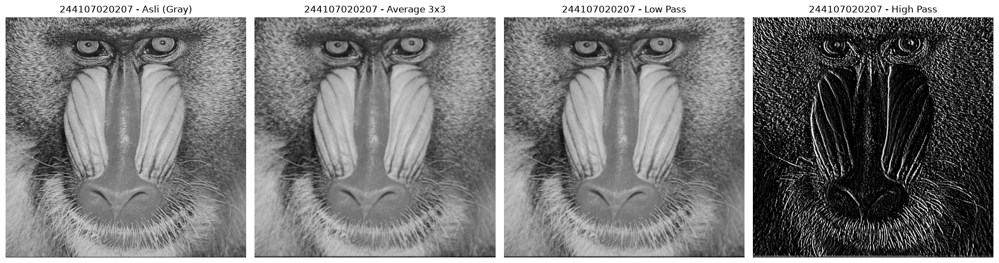

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\02_basic_sharpen_emboss_sobel.png


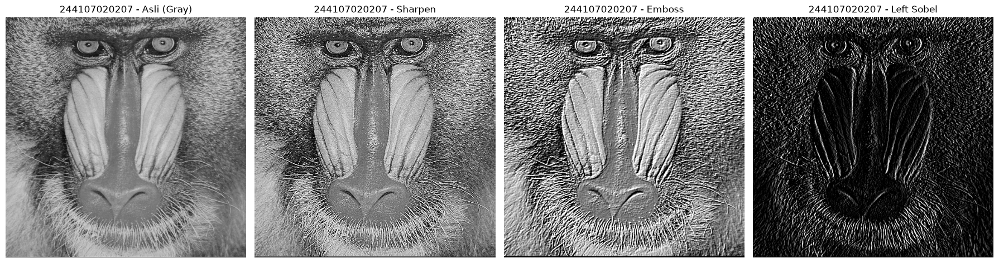

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\03_basic_laplacian_point.png


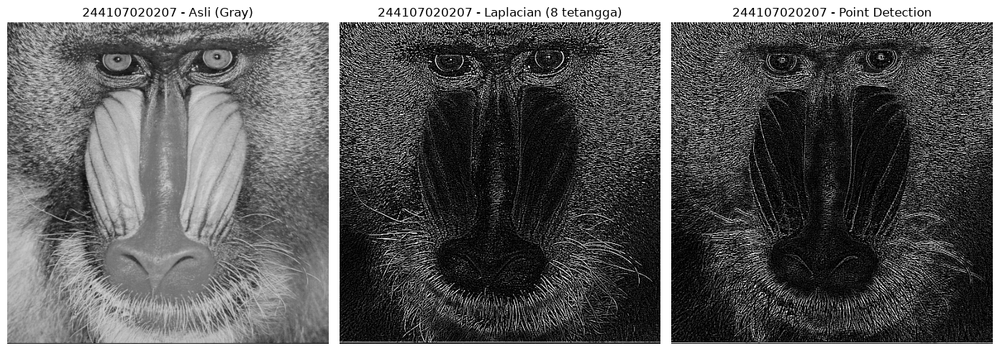

In [ ]:
hasil6 = {}
for nama, kern in KERNEL.items():
    hasil6[nama] = convolution2d(img_gray, kern, 1, 2)

show_side_by_side([img_gray] + [hasil6[n] for n in ['Average 3x3', 'Low Pass', 'High Pass']],
                  ['Asli (Gray)', 'Average 3x3', 'Low Pass', 'High Pass'],
                  figsize=(18, 5), nama='basic_lp_hp')

show_side_by_side([img_gray] + [hasil6[n] for n in ['Sharpen', 'Emboss', 'Sobel Kx']],
                  ['Asli (Gray)', 'Sharpen', 'Emboss', 'Left Sobel'],
                  figsize=(18, 5), nama='basic_sharpen_emboss_sobel')

show_side_by_side([img_gray] + [hasil6[n] for n in ['Laplacian', 'Point']],
                  ['Asli (Gray)', 'Laplacian (8 tetangga)', 'Point Detection'],
                  figsize=(14, 5), nama='basic_laplacian_point')

### 5.1 Gaussian Blur 21 x 21 dari `cv.getGaussianKernel`

sigma = 4.5826 | bentuk: (21, 21) | jumlah koefisien: 1.0 | koefisien maksimum: 0.007919


disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\04_gaussian21.png


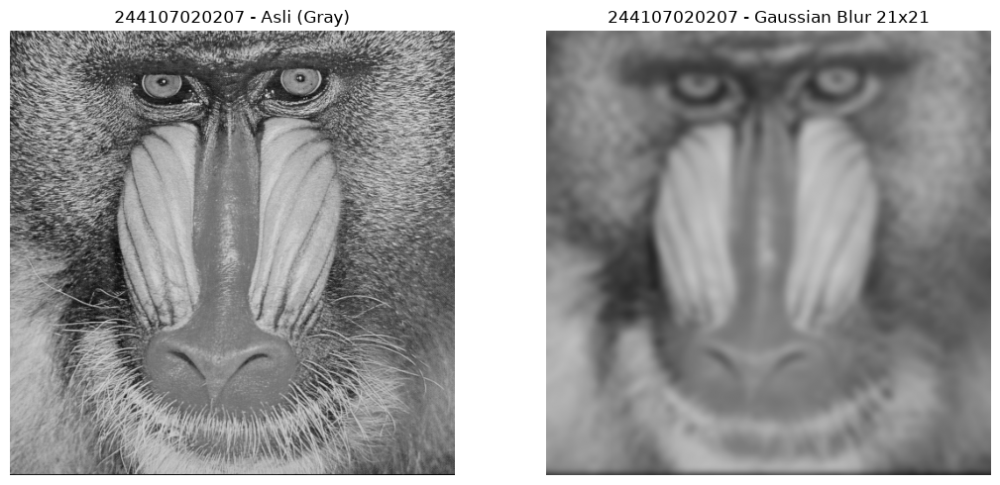

In [ ]:
kernel_size = 21
sigma = math.sqrt(kernel_size)
gk = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gk @ gk.transpose()
g21 = convolution2d(img_gray, gauss_kernel, 1, 10)
print("sigma =", round(sigma, 4), "| bentuk:", gauss_kernel.shape,
      "| jumlah koefisien:", round(float(gauss_kernel.sum()), 6),
      "| koefisien maksimum:", round(float(gauss_kernel.max()), 6))
show_side_by_side([img_gray, g21], ['Asli (Gray)', 'Gaussian Blur 21x21'],
                  figsize=(11, 5), nama='gaussian21')

## 6. Praktikum Filter Spasial Lanjutan (Percobaan 1-7)

Seluruh percobaan ini memakai `cv.filter2D` pada citra berwarna.

kue.JPG    : (537, 960, 3)
street.jpg : (960, 1280, 3)


disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\05_sumber_materi.png


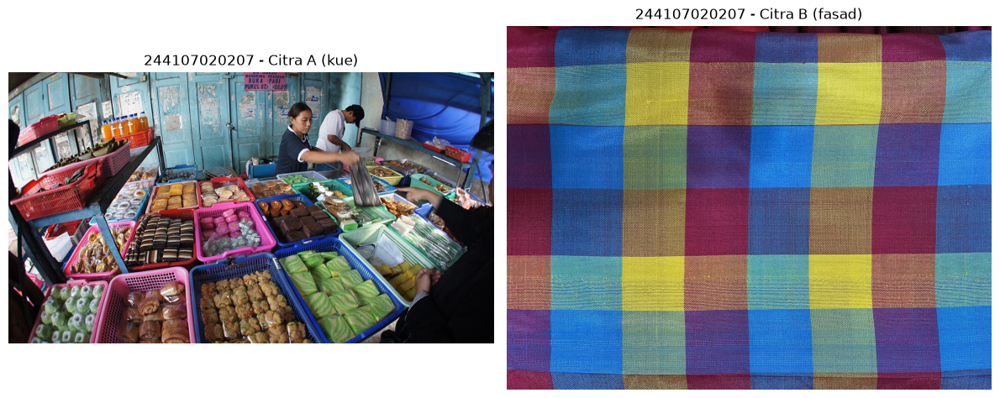

In [ ]:
img_c = cv.imread(os.path.join(IMAGES, 'kue.JPG'))        # tekstur warna rapat
img_s = cv.imread(os.path.join(IMAGES, 'street.jpg'))     # tepi dan garis struktur
if img_s is not None and img_s.shape[0] > img_s.shape[1]:
    img_s = cv.rotate(img_s, cv.ROTATE_90_CLOCKWISE)
print("kue.JPG    :", img_c.shape)
print("street.jpg :", img_s.shape)
show_side_by_side([img_c, img_s], ['Citra A (kue)', 'Citra B (fasad)'],
                  figsize=(12, 5), nama='sumber_materi')

### Percobaan 1 — Gaussian, Sharpen, dan deteksi tepi memakai library `filter2D`

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\06_p1_gaussian_sharpen.png


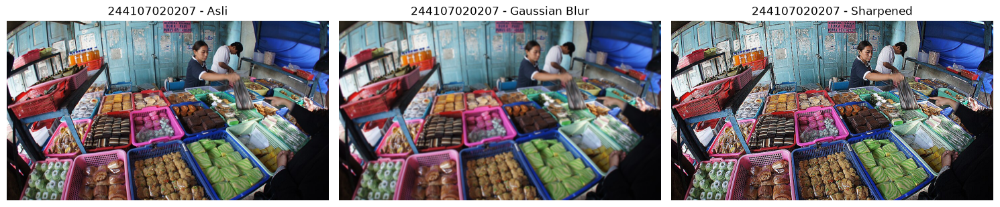

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\07_p1_filter2d_tepi.png


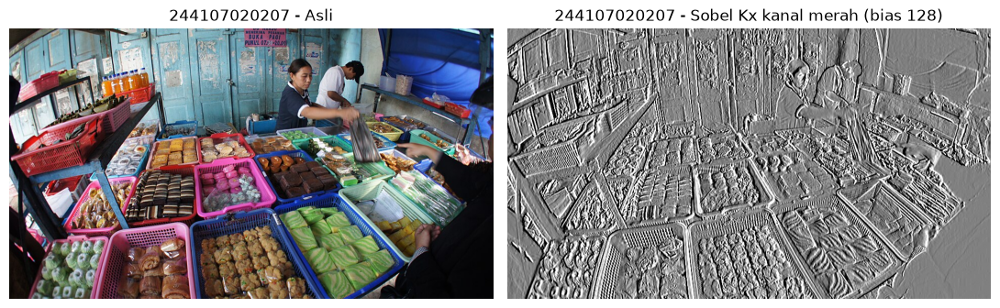

In [ ]:
k_gauss7 = cv.getGaussianKernel(7, 1.5) @ cv.getGaussianKernel(7, 1.5).T
blur  = cv.filter2D(img_c, -1, k_gauss7)
sharp = cv.filter2D(img_c, -1, k_sharpen)
show_side_by_side([img_c, blur, sharp],
                  ['Asli', 'Gaussian Blur', 'Sharpened'],
                  figsize=(15, 5), nama='p1_gaussian_sharpen')

# kernel deteksi tepi pada satu kanal; keluaran float dibias 128 agar terlihat
kanalR = img_c[:, :, 2]
sobel_R = np.clip(cv.filter2D(kanalR, cv.CV_32F, KERNEL['Sobel Kx']) + 128, 0, 255).astype(np.uint8)
show_side_by_side([img_c, sobel_R], ['Asli', 'Sobel Kx kanal merah (bias 128)'],
                  figsize=(11, 5), nama='p1_filter2d_tepi')

### Percobaan 2 — Canny dan filter modern library

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\08_p2_canny_laplacian.png


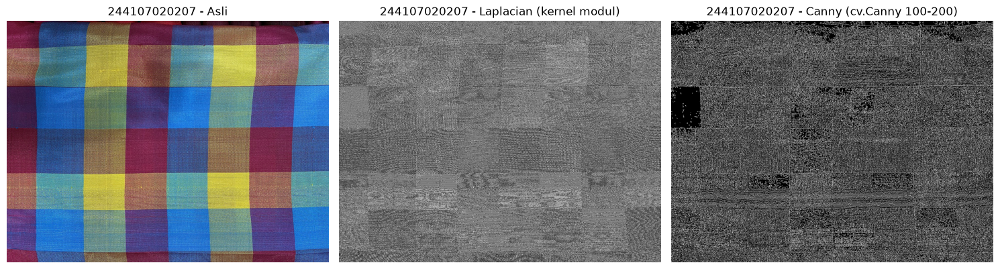

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\09_p2_bilateral_guided.png


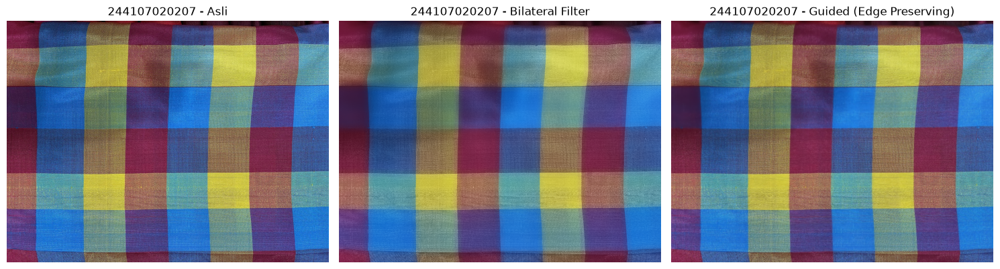

In [ ]:
edges = cv.Canny(img_s, 100, 200)
lap_s = np.clip(cv.filter2D(cv.cvtColor(img_s, cv.COLOR_BGR2GRAY), cv.CV_32F,
                            KERNEL['Laplacian']) + 128, 0, 255).astype(np.uint8)
show_side_by_side([img_s, lap_s, edges],
                  ['Asli', 'Laplacian (kernel modul)', 'Canny (cv.Canny 100-200)'],
                  figsize=(15, 5), nama='p2_canny_laplacian')

bilateral = cv.bilateralFilter(img_s, 50, 100, 100)
guided = cv.edgePreservingFilter(img_s, flags=1, sigma_s=100, sigma_r=0.9)
show_side_by_side([img_s, bilateral, guided],
                  ['Asli', 'Bilateral Filter', 'Guided (Edge Preserving)'],
                  figsize=(15, 5), nama='p2_bilateral_guided')

### Percobaan 3 — Filtering pada CNN (feature map)

bobot conv1 run-1 (mean abs) = 0.14471
bobot conv1 run-2 (mean abs) = 0.15081
selisih bobot antar run      = 0.5027


disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\10_p3_cnn_run1.png


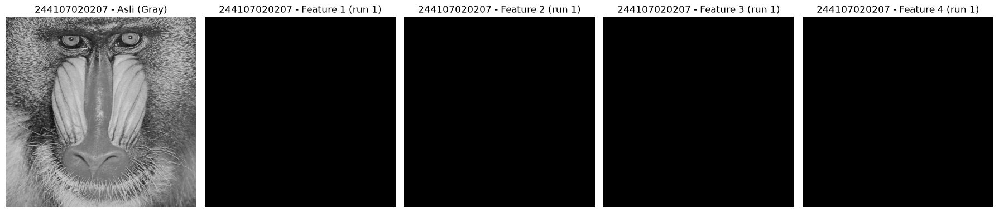

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\11_p3_cnn_run2.png


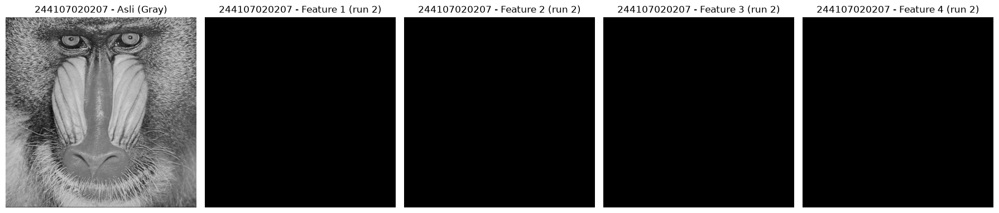

In [ ]:
import torch, torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self, n_out=4):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, n_out, kernel_size=3, stride=1, padding=1)
    def forward(self, x):
        return self.conv1(x)

img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

def feature_maps(seed):
    torch.manual_seed(seed)
    model = SimpleCNN()
    with torch.no_grad():
        f = model(img_tensor)
    return [f[0, i].numpy() for i in range(f.shape[1])], model.conv1.weight.detach().numpy()

fm1, w1 = feature_maps(1)
fm2, w2 = feature_maps(7)
print("bobot conv1 run-1 (mean abs) =", round(float(np.abs(w1).mean()), 5))
print("bobot conv1 run-2 (mean abs) =", round(float(np.abs(w2).mean()), 5))
print("selisih bobot antar run      =", round(float(np.abs(w1 - w2).max()), 5))
show_side_by_side([img_gray] + fm1,
                  ['Asli (Gray)'] + ['Feature %d (run 1)' % (i + 1) for i in range(4)],
                  figsize=(18, 5), nama='p3_cnn_run1')
show_side_by_side([img_gray] + fm2,
                  ['Asli (Gray)'] + ['Feature %d (run 2)' % (i + 1) for i in range(4)],
                  figsize=(18, 5), nama='p3_cnn_run2')

### Percobaan 4 — Filter Beauty dan Old/Vintage

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\12_p4_beauty_vintage.png


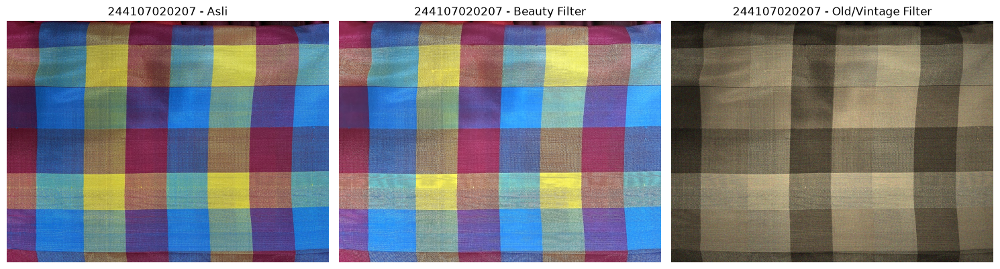

mask vignette: pusat 1.000, sudut 0.500


In [ ]:
# 1. Beauty Filter
smooth = cv.bilateralFilter(img_s, d=15, sigmaColor=75, sigmaSpace=75)
gaussian = cv.GaussianBlur(smooth, (0, 0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)
beauty = cv.convertScaleAbs(sharpened, alpha=1.2, beta=15)

# 2. Old/Vintage Filter
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = np.clip(cv.transform(img_s, sepia_kernel), 0, 255).astype(np.uint8)
rows, cols = img_s.shape[:2]
mask = cv.getGaussianKernel(rows, rows * 0.6) * cv.getGaussianKernel(cols, cols * 0.6).T
mask = mask / mask.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:, :, i] = np.clip(vignette[:, :, i] * mask, 0, 255)
noise = np.random.normal(0, 15, vignette.shape)
old_img = np.clip(vignette.astype(np.float64) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img_s, beauty, old_img],
                  ['Asli', 'Beauty Filter', 'Old/Vintage Filter'],
                  figsize=(15, 5), nama='p4_beauty_vintage')
print("mask vignette: pusat %.3f, sudut %.3f" % (mask[rows // 2, cols // 2], mask[0, 0]))

### Percobaan 5 — Filter Anime / Cartoon

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\13_p5_cartoon.png


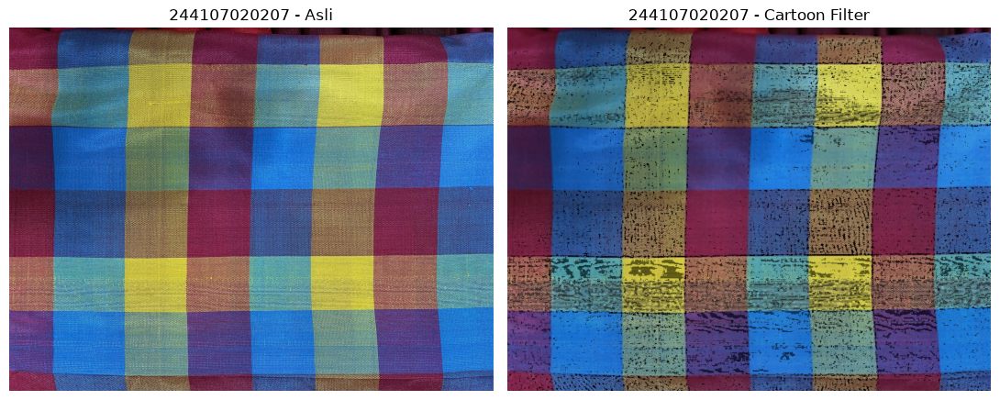

In [ ]:
gray_blur = cv.medianBlur(cv.cvtColor(img_s, cv.COLOR_BGR2GRAY), 7)
edges_cart = cv.adaptiveThreshold(gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C,
                                  cv.THRESH_BINARY, 9, 9)
color = cv.bilateralFilter(img_s, d=9, sigmaColor=200, sigmaSpace=200)
cartoon = cv.bitwise_and(color, color, mask=edges_cart)
show_side_by_side([img_s, cartoon], ['Asli', 'Cartoon Filter'],
                  figsize=(11, 5), nama='p5_cartoon')

### Percobaan 6 — Filter Malam

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\14_p6_night.png


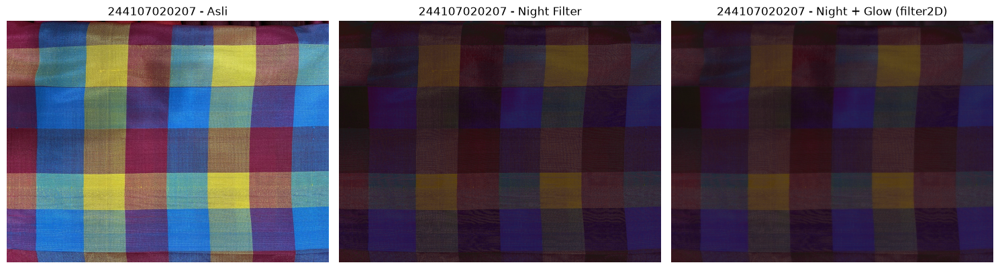

In [ ]:
night = cv.convertScaleAbs(img_s, alpha=0.6, beta=-40)
night = cv.addWeighted(night, 0.8, np.full_like(night, (50, 0, 100)), 0.2, 0)
glow = cv.filter2D(night, -1, np.ones((15, 15), np.float32) / 225)
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)
show_side_by_side([img_s, night, night_glow],
                  ['Asli', 'Night Filter', 'Night + Glow (filter2D)'],
                  figsize=(15, 5), nama='p6_night')

### Percobaan 7 — Filter Pagi dan Pagi + Kabut

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\15_p7_pagi_kabut.png


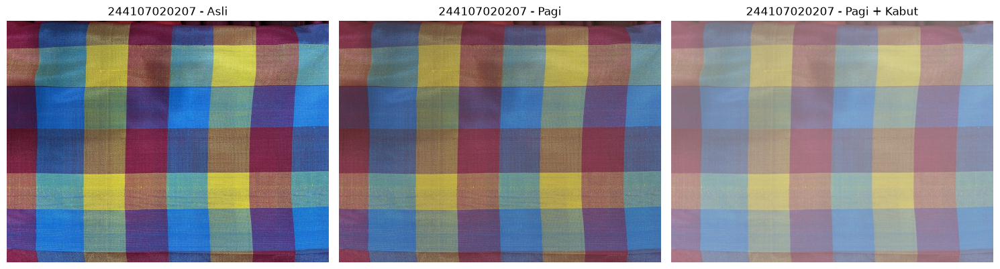

In [ ]:
soft = cv.convertScaleAbs(img_s, alpha=0.9, beta=20)
pagi = cv.addWeighted(soft, 0.8, np.full_like(soft, (40, 70, 120)), 0.2, 0)
kb = cv.getGaussianKernel(3, 3); kb = kb @ kb.T
kabut = cv.addWeighted(cv.filter2D(pagi, -1, kb), 0.7, np.full_like(pagi, 255), 0.3, 0)
show_side_by_side([img_s, pagi, kabut],
                  ['Asli', 'Pagi', 'Pagi + Kabut'],
                  figsize=(15, 5), nama='p7_pagi_kabut')

## 7. Tugas Praktikum 1 — Mean Filter vs Median Filter pada noise Salt and Pepper

densitas noise sesungguhnya : 0.0498
MAE mean 3x3   : 17.5735
MAE median 3x3 : 13.6319


disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\16_t1_mean_median.png


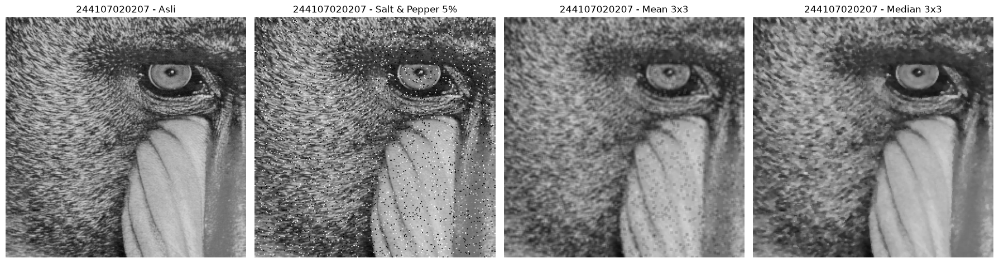

In [ ]:
def median_filter_manual(image, ksize=3):
    img = np.asarray(image, np.float64)
    p = ksize // 2
    pad = np.pad(img, p, mode='edge')
    out = np.empty_like(img)
    for x in range(img.shape[0]):
        for y in range(img.shape[1]):
            out[x, y] = np.median(pad[x:x + ksize, y:y + ksize])
    return out.astype(np.uint8)

def tambah_salt_pepper(image, densitas=0.05, seed=42):
    rng = np.random.default_rng(seed)
    out = image.copy()
    u = rng.random(image.shape)
    out[u < densitas / 2] = 0
    out[u > 1 - densitas / 2] = 255
    return out

def mae(a, b):
    return float(np.mean(np.abs(a.astype(np.float64) - b.astype(np.float64))))

kecil2 = img_gray[:256, :256]
sp = tambah_salt_pepper(kecil2, 0.05)
mean_m = convolution2d(sp, KERNEL['Average 3x3'], 1, 1)
median_m = median_filter_manual(sp, 3)

print("densitas noise sesungguhnya : %.4f" % float(np.mean((sp == 0) | (sp == 255))))
print("MAE mean 3x3   : %.4f" % mae(mean_m, kecil2))
print("MAE median 3x3 : %.4f" % mae(median_m, kecil2))
show_side_by_side([kecil2, sp, mean_m, median_m],
                  ['Asli', 'Salt & Pepper 5%', 'Mean 3x3', 'Median 3x3'],
                  figsize=(18, 5), nama='t1_mean_median')

## 8. Tugas Praktikum 2 — Kernel penajaman 3 x 3 dibandingkan 5 x 5

In [ ]:
def kernel_sharpen(n):
    """Pusat 1+4n, empat tetangga arah sumbu bernilai -1, sisanya 0."""
    k = np.zeros((n, n), np.float64)
    p = n // 2
    k[p, p] = 1 + 4 * n
    k[p - 1, p] = k[p + 1, p] = k[p, p - 1] = k[p, p + 1] = -1
    return k

k3, k5 = kernel_sharpen(3), kernel_sharpen(5)
print("kernel 3x3 jumlah koefisien = %.1f" % k3.sum()); print(k3.astype(int))
print("kernel 5x5 jumlah koefisien = %.1f" % k5.sum()); print(k5.astype(int))

kernel 3x3 jumlah koefisien = 9.0
[[ 0 -1  0]
 [-1 13 -1]
 [ 0 -1  0]]
kernel 5x5 jumlah koefisien = 17.0
[[ 0  0  0  0  0]
 [ 0  0 -1  0  0]
 [ 0 -1 21 -1  0]
 [ 0  0 -1  0  0]
 [ 0  0  0  0  0]]


Asli         var Laplacian =   6563.51 | noise petak datar =  34.54
Buram        var Laplacian =     60.16 | noise petak datar =  22.21
Sharpen 3x3  var Laplacian =      5.53 | noise petak datar =   0.45
Sharpen 5x5  var Laplacian =      0.13 | noise petak datar =   0.02


disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\17_t2_kernel.png


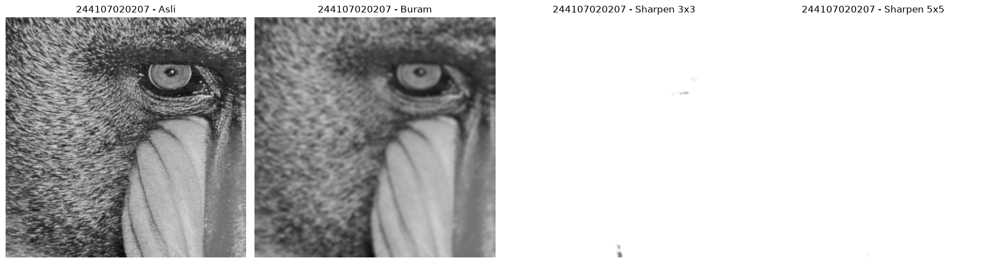

In [ ]:
def var_laplacian(g):
    """Varians Laplacian: makin tinggi makin tajam."""
    return float(cv.Laplacian(g, cv.CV_64F).var())

def noise_datar(g, blok=32):
    """Rerata simpangan baku tiap petak datar: makin kecil makin halus."""
    sd = [g[r:r + blok, c:c + blok].std()
          for r in range(0, g.shape[0] - blok + 1, blok)
          for c in range(0, g.shape[1] - blok + 1, blok)]
    return float(np.mean(sd))

buram = cv.GaussianBlur(kecil2, (5, 5), 1.5)
s3 = convolution2d(buram, k3, 1, 1)
s5 = convolution2d(buram, k5, 1, 2)
ukur = [("Asli", kecil2), ("Buram", buram), ("Sharpen 3x3", s3), ("Sharpen 5x5", s5)]
for nama, g in ukur:
    print("%-12s var Laplacian = %9.2f | noise petak datar = %6.2f" % (nama, var_laplacian(g), noise_datar(g)))
show_side_by_side([kecil2, buram, s3, s5],
                  ['Asli', 'Buram', 'Sharpen 3x3', 'Sharpen 5x5'],
                  figsize=(18, 5), nama='t2_kernel')

## 9. Tugas Praktikum 3 — Filter Kartun Sederhana

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\18_tugas3_kartun.png


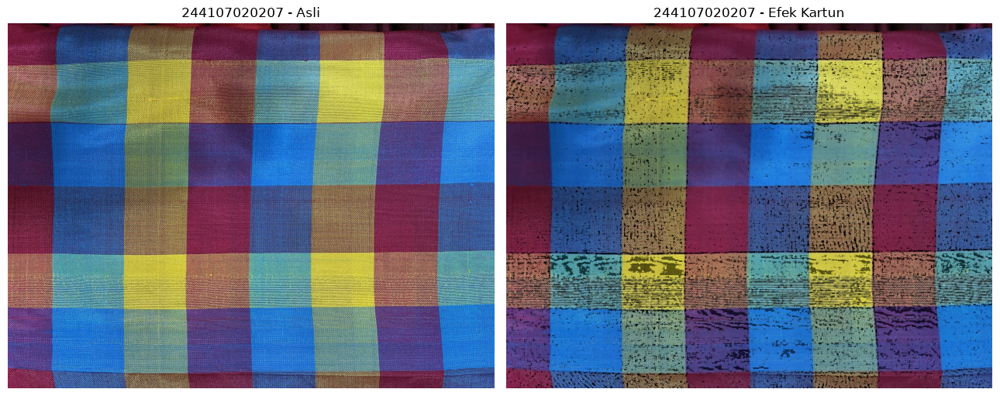

disimpan: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\19_tugas3_variasi.png


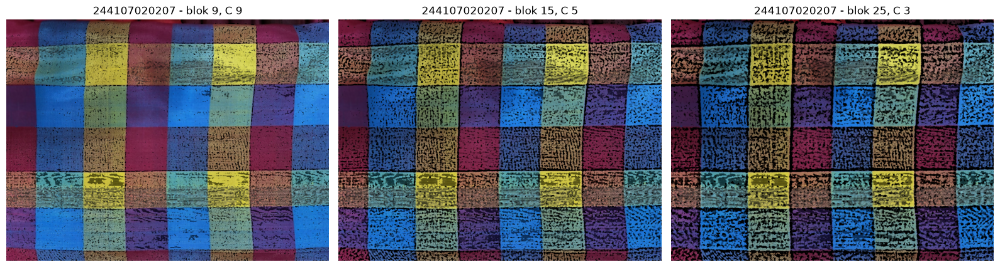

blok09_C09 -> proporsi piksel garis (nilai 0) = 0.0975
blok15_C05 -> proporsi piksel garis (nilai 0) = 0.2595
blok25_C03 -> proporsi piksel garis (nilai 0) = 0.3774


In [ ]:
def kartun(image, d=9, sigmaColor=150, sigmaSpace=150, blok=9, C=9, ksize=7):
    """Penghalusan bilateral + garis tepi adaptive threshold, digabung operasi logika."""
    halus = cv.bilateralFilter(image, d=d, sigmaColor=sigmaColor, sigmaSpace=sigmaSpace)
    abu = image if image.ndim == 2 else cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    tepi = cv.adaptiveThreshold(cv.medianBlur(abu, ksize), 255,
                                cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, blok, C)
    return cv.bitwise_and(halus, halus, mask=tepi)

hasil_kartun = kartun(img_s)
show_side_by_side([img_s, hasil_kartun], ['Asli', 'Efek Kartun'],
                  figsize=(13, 6), nama='tugas3_kartun')

var = {}
for blok, C in [(9, 9), (15, 5), (25, 3)]:
    var["blok%02d_C%02d" % (blok, C)] = kartun(img_s, blok=blok, C=C)
kunci = list(var)
show_side_by_side([var[k] for k in kunci], ['blok 9, C 9', 'blok 15, C 5', 'blok 25, C 3'],
                  figsize=(16, 5), nama='tugas3_variasi')
for k in kunci:
    print("%s -> proporsi piksel garis (nilai 0) = %.4f"
          % (k, float(np.mean(cv.cvtColor(var[k], cv.COLOR_BGR2GRAY) == 0))))

## 10. Ekspor hasil.json

In [ ]:
import json
hasil = {
    "nama": NAMA, "nim": NIM, "no_absen": NO_ABSEN, "token": TOKEN, "N": N,
    "waktu": datetime.datetime.now().astimezone().isoformat(),
    "mandrill_shape": list(img.shape),
    "mandrill_gray_shape": list(img_gray.shape),
    "verifikasi_ukuran": list(manual.shape),
    "verifikasi_konvolusi_selisih_maks": selisih,
    "gaussian21_sigma": round(float(math.sqrt(21)), 6),
    "gaussian21_jumlah_koef": round(float(gauss_kernel.sum()), 6),
    "gaussian21_koef_maks": round(float(gauss_kernel.max()), 6),
    "terang_asli": float(img_gray.mean()), "terang_blur21": float(g21.mean()),
    "terang_lowpass": float(hasil6['Low Pass'].mean()),
    "terang_highpass": float(hasil6['High Pass'].mean()),
    "kontras_asli": float(img_gray.std()), "kontras_highpass": float(hasil6['High Pass'].std()),
    "t1_densitas": float(np.mean((sp == 0) | (sp == 255))),
    "t1_mae_mean": mae(mean_m, kecil2), "t1_mae_median": mae(median_m, kecil2),
    "t1_sisa_mean": float(np.mean((mean_m == 0) | (mean_m == 255))),
    "t1_sisa_median": float(np.mean((median_m == 0) | (median_m == 255))),
    "t1_sisa_asli": float(np.mean((kecil2 == 0) | (kecil2 == 255))),
    "t2_var_laplacian": {n: var_laplacian(g) for n, g in ukur},
    "t2_noise_datar": {n: noise_datar(g) for n, g in ukur},
    "t3_jumlah_garis": {k: float(np.mean(cv.cvtColor(var[k], cv.COLOR_BGR2GRAY) == 0)) for k in kunci},
    "p3_bobot_mean": [round(float(np.abs(w1).mean()), 5), round(float(np.abs(w2).mean()), 5)],
    "p3_selisih_bobot_maks": round(float(np.abs(w1 - w2).max()), 5),
    "p4_mask_pusat": float(mask[rows // 2, cols // 2]), "p4_mask_sudut": float(mask[0, 0]),
}
open(os.path.join(OUT, 'hasil.json'), 'w').write(json.dumps(hasil, indent=1, ensure_ascii=False))
print("hasil.json:", os.path.join(OUT, 'hasil.json'), "|", len(hasil), "kunci")
print("Total gambar tersimpan:", FIG[0])

hasil.json: C:\Kuliah\Tingkat 3\PCVK\Week 6\materi\out\hasil.json | 32 kunci
Total gambar tersimpan: 19
